# Setup

In [ ]:
# from google.colab import files
# files.upload()

!pip install kagglehub


In [ ]:
import kagglehub
from google.colab import userdata
import os
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

path = kagglehub.dataset_download("yash92328/ai4mars-terrainaware-autonomous-driving-on-mars")
print(path)

100%|██████████| 5.72G/5.72G [02:33<00:00, 39.9MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1


In [ ]:
import glob

MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
print("msl folder:", MSL)

EDR_DIR = os.path.join(MSL, "images", "edr")
MXY_DIR = os.path.join(MSL, "images", "mxy")
RNG_DIR = os.path.join(MSL, "images", "rng-30m")
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
print(os.listdir(os.path.join(MSL, "labels", "test")))

msl folder: /root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl
['masked-gold-min2-100agree', 'masked-gold-min1-100agree', 'masked-gold-min3-100agree']


In [ ]:
TEST_LABEL_DIR = os.path.join(MSL, "labels", "test", "masked-gold-min3-100agree")

for name, d in [("edr", EDR_DIR), ("mxy", MXY_DIR), ("rng", RNG_DIR),
                ("train labels", TRAIN_LABEL_DIR), ("test labels", TEST_LABEL_DIR)]:
    files = sorted(os.listdir(d))
    print(f"{name}: {len(files)} files, e.g. {files[:2]}")

edr: 18130 files, e.g. ['NLA_397586928EDR_F0010008AUT_04096M1.JPG', 'NLA_397586934EDR_F0010008AUT_04096M1.JPG']
mxy: 18097 files, e.g. ['NLA_397586928MXY_F0010008AUT_04096M1.png', 'NLA_397586934MXY_F0010008AUT_04096M1.png']
rng: 18096 files, e.g. ['NLA_397586928RNG_F0010008AUT_04096M1.png', 'NLA_397586934RNG_F0010008AUT_04096M1.png']
train labels: 16064 files, e.g. ['NLA_397586934EDR_F0010008AUT_04096M1.png', 'NLA_397681339EDR_F0020000AUT_04096M1.png']
test labels: 322 files, e.g. ['NLA_409036068EDR_F0051606NCAM00348M1_merged.png', 'NLA_409036116EDR_F0051606NCAM00348M1_merged.png']


# Task #1: Random sample

In [ ]:
import random

train_labels = sorted(f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png"))
test_labels = sorted(f for f in os.listdir(TEST_LABEL_DIR) if f.endswith(".png"))

random.seed(42)
train_sample = random.sample(train_labels, 500)
test_sample = random.sample(test_labels, 125)

print(len(train_sample), "train", len(test_sample), "test")
print(train_sample[:3])
print(test_sample[:3])

500 train 125 test
['NLB_532342701EDR_F0592578NCAM00279M1.png', 'NLB_424934381EDR_F0060658NCAM00247M1.png', 'NLA_402816098EDR_F0050104NCAM00451M1.png']
['NLB_520358689EDR_F0550940NCAM00299M1_merged.png', 'NLB_436384026EDR_F0211362NCAM00279M1_merged.png', 'NLB_463814218EDR_F0420000NCAM00354M1_merged.png']


In [ ]:
# Making sure we get the right amount of files, no duplicates, and that all the files are real train files

print(len(train_sample) == 500, len(test_sample) == 125) # checks if file amount is right
print(len(set(train_sample)) == 500) # checks for duplicates
print(all(f in train_labels for f in train_sample)) # checks if all train files are real

True True
True
True


# Task #2: Check files, sizes, and label values

In [ ]:
def get_paths(label_file, split):
  """Given a label file name, return the paths to its photo, masks, and label."""
  base = label_file.replace(".png", "")
  if split == "test":
    base = base.replace("_merged", "")
    label_dir = TEST_LABEL_DIR
  else:
    label_dir = TRAIN_LABEL_DIR

  return {
      "edr":   os.path.join(EDR_DIR, base + ".JPG"),
      "mxy":   os.path.join(MXY_DIR, base.replace("EDR", "MXY") + ".png"),
      "rng":   os.path.join(RNG_DIR, base.replace("EDR", "RNG") + ".png"),
      "label": os.path.join(label_dir, label_file),
  }

print(get_paths(train_sample[0], "train"))
print(get_paths(test_sample[0], "test"))

{'edr': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_532342701EDR_F0592578NCAM00279M1.JPG', 'mxy': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/mxy/NLB_532342701MXY_F0592578NCAM00279M1.png', 'rng': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/rng-30m/NLB_532342701RNG_F0592578NCAM00279M1.png', 'label': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/labels/train/NLB_532342701EDR_F0592578NCAM00279M1.png'}
{'edr': '/root/.cache/kagglehub/datasets/yash92328/ai4mars-terrainaware-autonomous-driving-on-mars/versions/1/ai4mars-dataset-merged-0.1/msl/images/edr/NLB_520358689EDR_F0550940NCAM00299M1.JPG', 'mxy': '/root/.cache

In [ ]:
import numpy as np
from PIL import Image

ALLOWED = {0, 1, 2, 3, 255}

def check(label_file, split):
  """Return a list of problems with this image. An empty list means it passed."""
  paths = get_paths(label_file, split)

  # First check to make sure all the files exist
  problems = []
  for kind, p in paths.items():
    if not os.path.exists(p):
      problems.append(f"missing {kind}")
  if problems:
    return problems

  # Second check to mae sure all four are hte same size
  sizes = {kind: Image.open(p).size for kind, p in paths.items()}
  if len(set(sizes.values())) > 1:
    problems.append(f"size mismatch {sizes}")

  # Third check to make sure that the label only uses allowed values
  label = np.array(Image.open(paths["label"]))
  bad = set(np.unique(label).tolist()) - ALLOWED
  if bad:
    problems.append(f"bad label values {bad}")

  return problems

print(check(train_sample[0], "train"))

[]


In [ ]:
# Just making sure checker can actually fail
print(check("NLA_FAKE123EDR_TEST.png", "train"))

['missing edr', 'missing mxy', 'missing rng', 'missing label']


In [ ]:
results = []
for split, sample in [("train", train_sample), ("test", test_sample)]:
  for f in sample:
    results.append({"split": split, "label_file": f, "problems": check(f, split)})

failed = [r for r in results if r["problems"]]
print(f"{len(failed)} of {len(results)} images failed")
for r in failed:
  print(r["split"], r["label_file"], r["problems"])

0 of 625 images failed


In [ ]:
import pandas as pd

rows = []
for r in results:
  paths = get_paths(r["label_file"], r["split"])
  row = {"split": r["split"]}
  for kind, p in paths.items():
    row[kind] = os.path.relpath(p, MSL)
  row["passed"] = len(r["problems"]) == 0
  rows.append(row)

df = pd.DataFrame(rows)
df.to_csv("sample_split.csv", index=False)
print(df.shape)
df.head()

(625, 6)


,split,edr,mxy,rng,label,passed
0,train,images/edr/NLB_532342701EDR_F0592578NCAM00279M...,images/mxy/NLB_532342701MXY_F0592578NCAM00279M...,images/rng-30m/NLB_532342701RNG_F0592578NCAM00...,labels/train/NLB_532342701EDR_F0592578NCAM0027...,True
1,train,images/edr/NLB_424934381EDR_F0060658NCAM00247M...,images/mxy/NLB_424934381MXY_F0060658NCAM00247M...,images/rng-30m/NLB_424934381RNG_F0060658NCAM00...,labels/train/NLB_424934381EDR_F0060658NCAM0024...,True
2,train,images/edr/NLA_402816098EDR_F0050104NCAM00451M...,images/mxy/NLA_402816098MXY_F0050104NCAM00451M...,images/rng-30m/NLA_402816098RNG_F0050104NCAM00...,labels/train/NLA_402816098EDR_F0050104NCAM0045...,True
3,train,images/edr/NLB_550280573EDR_F0633092NCAM00312M...,images/mxy/NLB_550280573MXY_F0633092NCAM00312M...,images/rng-30m/NLB_550280573RNG_F0633092NCAM00...,labels/train/NLB_550280573EDR_F0633092NCAM0031...,True
4,train,images/edr/NLB_454665258EDR_F0331036NCAM00293M...,images/mxy/NLB_454665258MXY_F0331036NCAM00293M...,images/rng-30m/NLB_454665258RNG_F0331036NCAM00...,labels/train/NLB_454665258EDR_F0331036NCAM0029...,True


**Result:** 0 of 625 sampled images failed. All have edr/mxy/rng/label files, matching sizes, and only label values {0, 1, 2, 3, 255}.

Note: the full dataset has 33 photos missing MXY masks and 34 missing RNG masks, but none landed in this sample.

# Task #3: Check images, create threshold

In [ ]:
# hey guys
import matplotlib.pyplot as plt

NULL_VALUE = 255

def labeled_fraction(label_file, split):
  """Return the fraction of pixels in a label that are NOT 255 (i.e. labeled)."""
  paths = get_paths(label_file, split)
  label = np.array(Image.open(paths["label"]))
  return (label != NULL_VALUE).sum() / label.size

# Test it on one image before running everything
# print(labeled_fraction(train_sample[0], "train"))

# Add label_file and labeled_frac to the df from Task #2
df["label_file"] = [r["label_file"] for r in results]
df["labeled_frac"] = [labeled_fraction(r["label_file"], r["split"]) for r in results]

print(df.groupby("split")["labeled_frac"].describe())

       count      mean       std  min       25%       50%       75%       max
split                                                                        
test   125.0  0.365718  0.256233  0.0  0.148805  0.353882  0.571998  0.908750
train  500.0  0.541216  0.246395  0.0  0.356939  0.573856  0.746091  0.975905


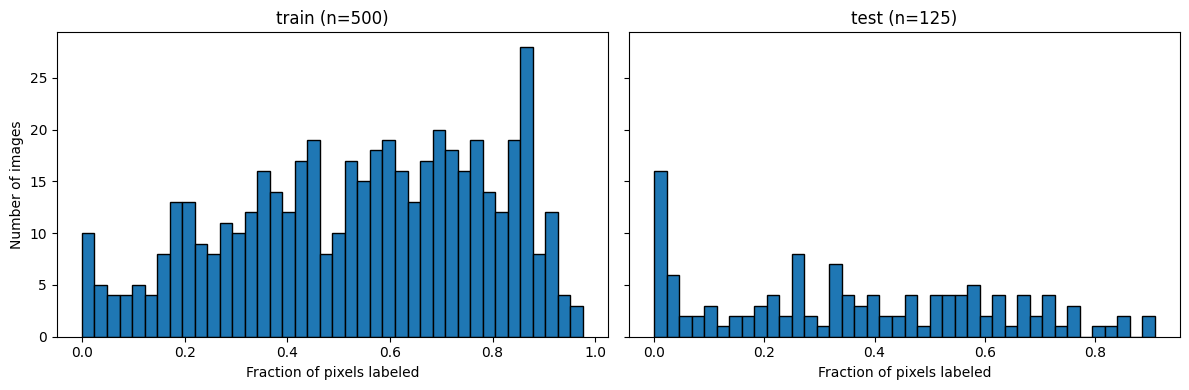

In [ ]:
# Plot 1: histogram of labeled fraction

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split in zip(axes, ["train", "test"]):
  vals = df.loc[df.split == split, "labeled_frac"]
  ax.hist(vals, bins=40, edgecolor="black")
  ax.set_title(f"{split} (n={len(vals)})")
  ax.set_xlabel("Fraction of pixels labeled")
axes[0].set_ylabel("Number of images")
plt.tight_layout()
plt.show()

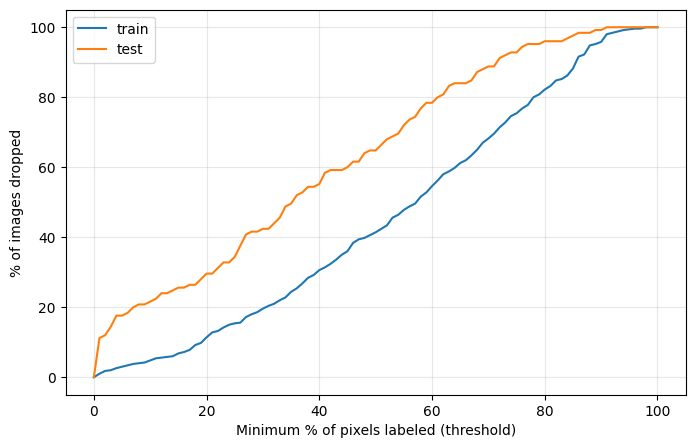

In [ ]:
# Plot 2: how many images would each threshold drop?

thresholds = np.linspace(0, 1, 101)

plt.figure(figsize=(8, 5))
for split in ["train", "test"]:
  vals = df.loc[df.split == split, "labeled_frac"].values
  dropped = [(vals < t).mean() * 100 for t in thresholds]
  plt.plot(thresholds * 100, dropped, label=split)

plt.xlabel("Minimum % of pixels labeled (threshold)")
plt.ylabel("% of images dropped")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Apply the threshold

THRESHOLD = 0.10  # may change later

# Keep all test images; only filter train
df["keep"] = (df["split"] == "test") | (df["labeled_frac"] >= THRESHOLD)

print(df.groupby("split")["keep"].agg(kept="sum", total="count"))
print(f"Dropped: {(~df.keep).sum()} of {len(df)}")

df.to_csv("sample_split_filtered.csv", index=False)

df_kept = df[df.keep]
print(df_kept.shape)

       kept  total
split             
test    125    125
train   476    500
Dropped: 24 of 625
(601, 9)


# Task #4: Pixel Count

In [ ]:
import os
import glob
import random
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Load the dataset
path = kagglehub.dataset_download(
    "yash92328/ai4mars-terrainaware-autonomous-driving-on-mars"
)
MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
NULL_VALUE = 255

# Use the same 500-image training subset as Task 1
train_labels = sorted(
    f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png")
)
random.seed(42)
train_sample = random.sample(train_labels, 500)

CLASSES = [0, 1, 2, 3]
CLASS_LABELS = ["soil", "bedrock", "sand", "big rock"]
N = len(train_sample)

pixel_counts = np.zeros(len(CLASSES), dtype=np.int64)
image_counts = np.zeros(len(CLASSES), dtype=np.int64)
heat = None
labeled_total = 0
resized = 0

In [ ]:
# Count pixels and images containing each class
for f in train_sample:
  with Image.open(os.path.join(TRAIN_LABEL_DIR, f)) as img:
    label = np.array(img)

  counts = np.bincount(label[label != NULL_VALUE], minlength=len(CLASSES))
  pixel_counts += counts
  image_counts += counts > 0
  labeled_total += (label != NULL_VALUE).sum()

  # Resize only for the heatmaps; pixel counts use the original size
  if heat is None:
    heat = np.zeros((len(CLASSES),) + label.shape)
  if label.shape != heat.shape[1:]:
    label = np.array(Image.fromarray(label).resize(
        (heat.shape[2], heat.shape[1]), resample=Image.NEAREST
    ))
    resized += 1

  for c in CLASSES:
    heat[c] += label == c

heat /= N

500 training images, heatmap size 1024x1024, 0 masks resized
   class    pixels  % of labeled pixels  images with class  % of images
    soil 105264360                37.10                252         50.4
 bedrock 140456739                49.50                323         64.6
    sand  34015503                11.99                179         35.8
big rock   4016638                 1.42                 80         16.0


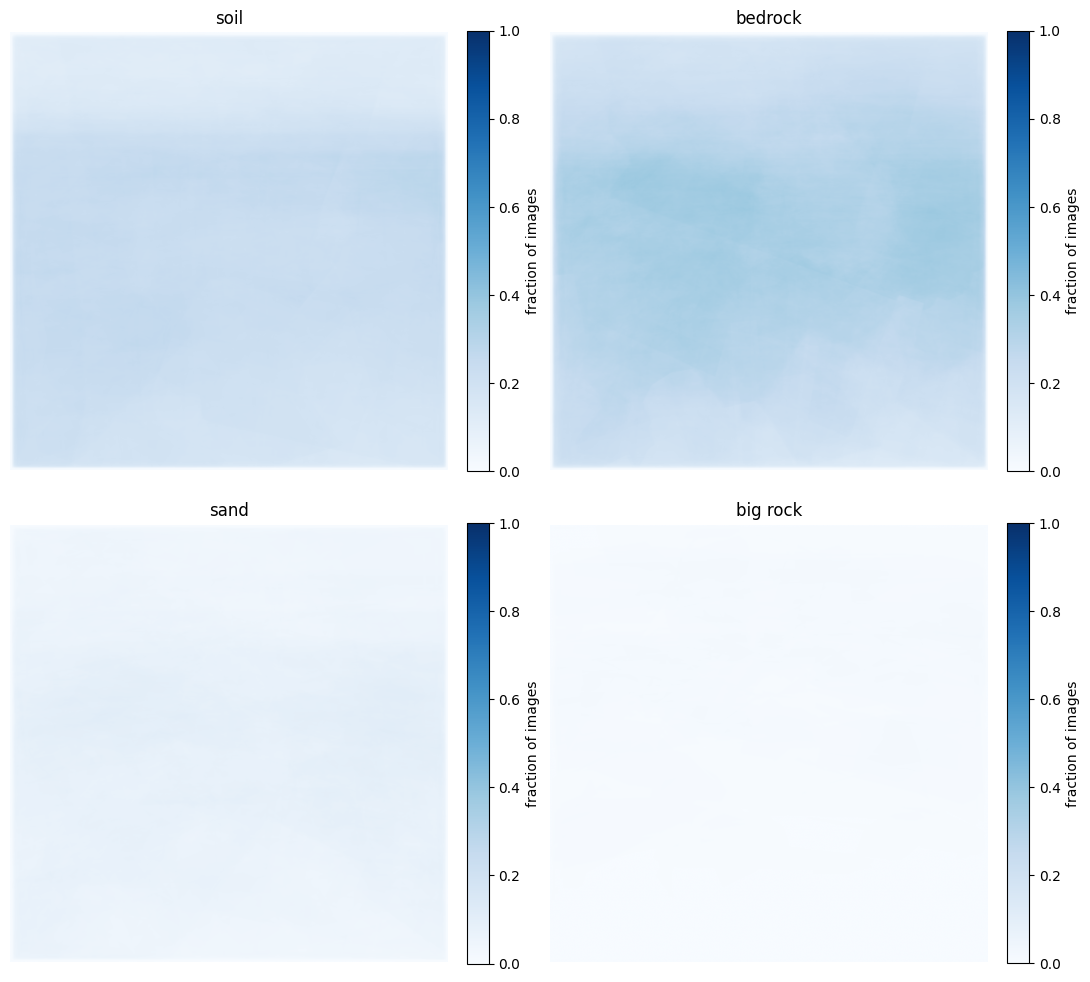

In [ ]:
# Sanity checks
assert pixel_counts.sum() == labeled_total
assert (image_counts <= N).all()
assert heat.min() >= 0 and heat.max() <= 1

print(f"{N} training images, heatmap size {heat.shape[1]}x{heat.shape[2]}, {resized} masks resized")

# Class summary (excluding void/null pixels)
summary = pd.DataFrame({
    "class": CLASS_LABELS,
    "pixels": pixel_counts,
    "% of labeled pixels": (
        pixel_counts / max(labeled_total, 1) * 100
    ).round(2),
    "images with class": image_counts,
    "% of images": (image_counts / N * 100).round(1),
})
print(summary.to_string(index=False))

# Heatmaps: fraction of sampled images with each class at each position
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, c in zip(axes.flat, CLASSES):
  im = ax.imshow(heat[c], cmap="Blues", vmin=0, vmax=1, origin="upper")
  ax.set_title(CLASS_LABELS[c])
  ax.axis("off")
  fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="fraction of images")

plt.tight_layout()
plt.show()

# Task #6 and # 7 : Map Class to more Distrinct Colors

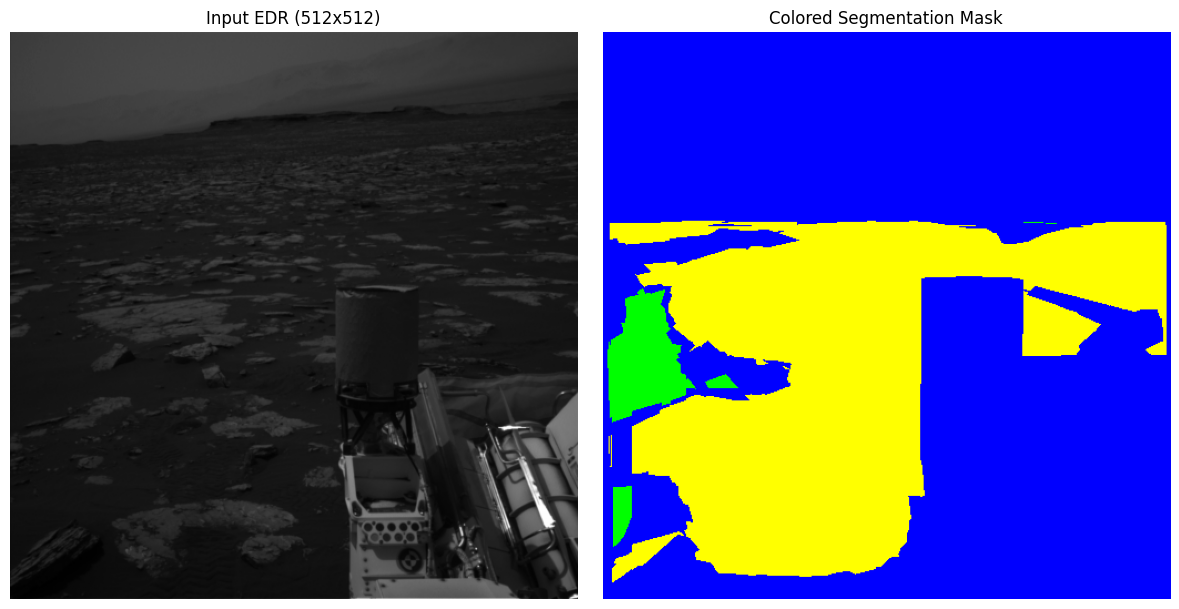

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

target_size = (512, 512)

color_map = {
    0 : [255, 0, 0],
    1 : [255, 255, 0],
    2 : [0, 255, 0],
    3 : [0, 255, 255],
    255 : [0, 0, 255],
}

class_names = {
    0 : "soil",
    1 : "bedrock",
    2 : "sand",
    3 : "Big Rock",
    255 :"void/null"
}

def load_and_resize (edr_path,label_path, target_size = target_size):
    edr_image = Image.open(edr_path).convert('L')
    edr_resized = edr_image.resize(target_size, resample = Image.BILINEAR)
    edr_arr = np.array(edr_resized)

    label_img = Image.open(label_path)
    label_resized = label_img.resize(target_size , resample = Image.NEAREST)
    label_arr = np.array(label_resized)

    return edr_arr, label_arr

def colorize_mask (label_arr):
    colored_mask = np.zeros((512, 512, 3), dtype = np.uint8)

    for class_ids, colors in color_map.items() :
        colored_mask[label_arr == class_ids] = colors
    return colored_mask

sample = df_kept.iloc[0]
sample_edr = os.path.join(MSL, sample['edr'])
sample_label = os.path.join(MSL, sample['label'])

edr_arr, label_arr = load_and_resize(sample_edr, sample_label)
colored_mask = colorize_mask(label_arr)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(edr_arr, cmap='gray')
axes[0].set_title(f"Input EDR ({target_size[0]}x{target_size[1]})")
axes[0].axis('off')

axes[1].imshow(colored_mask)
axes[1].set_title("Colored Segmentation Mask")
axes[1].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import os
import zipfile
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

local_extract_path = '/content/ai4mars_subset'
os.makedirs(local_extract_path, exist_ok=True)

zip_drive_path = '/content/drive/MyDrive/AI4Mars_Subset/ai4mars_subset.zip'
if len(os.listdir(local_extract_path)) == 0:
    print("Extracting subset from Google Drive... This is much faster than downloading the full dataset!")
    with zipfile.ZipFile(zip_drive_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_path)
    print("Extraction complete!")
else:
    print("Subset already extracted locally.")

MSL = local_extract_path
print("MSL root path is now set to:", MSL)

df_kept = pd.read_csv('/content/drive/MyDrive/AI4Mars_Subset/sample_split_filtered.csv')
print(f"Loaded metadata successfully. Total active samples: {len(df_kept)}")

Mounted at /content/drive
Extracting subset from Google Drive... This is much faster than downloading the full dataset!
Extraction complete!
MSL root path is now set to: /content/ai4mars_subset
Loaded metadata successfully. Total active samples: 1236


# SegFormer experiments

Uses the latest subset zip: 864 train masks and 372 test masks (the 322 min2 test images plus 50 extra big-rock images).

Several versions of SegFormer are trained (listed in EXPERIMENTS in the settings cell) and compared on the same test set:

1. Loss and mIoU vs epochs for each version, plus one graph with all versions together
2. Per-class IoU and a confusion matrix for each version
3. Random test images: photo, true mask, and each version's prediction
4. The best version is exported for the Streamlit demo

Runs top to bottom with Run all. Each version saves to its own folder in Drive. A finished version is skipped next time, and an unfinished one continues from its last finished epoch after a disconnect. Set RETRAIN = True to train everything again.

Note: the test set is also used to pick each version's best epoch and the best version, the same way for every model in the group. That keeps the comparison fair, but the scores are slightly optimistic for brand-new images.

In [1]:
# Setup: install, imports, GPU check, Drive

!pip install -q segmentation-models-pytorch

import os, json, time, random, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from google.colab import drive

# Needs a GPU: Runtime > Change runtime type > T4 GPU
print("GPU available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU. Switch the runtime to T4 GPU and run again."

drive.mount("/content/drive")

GPU available: True
Mounted at /content/drive


In [8]:
# Settings. Change values here, not further down.

SEED = 42
NUM_CLASSES = 4
CLASS_NAMES = ["soil", "bedrock", "sand", "big rock"]
IGNORE = 255              # unlabeled pixels, skipped in the loss and in IoU
USE_AMP = True            # mixed precision: faster on the GPU, same results in practice
RETRAIN = False           # True = train every version again even if it is saved

# Versions to train. Each one gets its own folder. Set "run" to False to skip one.
# b0 = smallest encoder, b2 = bigger and slower. "augment" = random crops, flips and brightness changes.
EXPERIMENTS = [
    #{"name": "b0",     "encoder": "mit_b0", "size": 512, "batch_size": 16, "lr": 1e-4, "epochs": 20, "augment": False, "run": True},
    #{"name": "b0_aug", "encoder": "mit_b0", "size": 512, "batch_size": 16, "lr": 1e-4, "epochs": 20, "augment": True,  "run": True},
    {"name": "b2_aug", "encoder": "mit_b2", "size": 512, "batch_size": 8,  "lr": 1e-4, "epochs": 20, "augment": True,  "run": True},
]

N_EXAMPLES = 4            # random test images to show
EXAMPLE_SEED = 7          # change to show different random images

# Data
SUBSET_ZIP = "/content/drive/MyDrive/AI4Mars_Subset/ai4mars_subset.zip"
SUBSET_ROOT = "/content/ai4mars_subset"

# Outputs, saved in Drive so they survive a runtime reset
RUNS_ROOT = "/content/drive/MyDrive/segformer_runs_v2"
EXPORT_DIR = f"{RUNS_ROOT}/streamlit"
os.makedirs(EXPORT_DIR, exist_ok=True)

# Colors match Task 6/7: soil red, bedrock yellow, sand green, big rock cyan, unlabeled blue
COLORS = {0: [255, 0, 0], 1: [255, 255, 0], 2: [0, 255, 0], 3: [0, 255, 255], 255: [0, 0, 255]}

device = "cuda"

In [3]:
# Get the data on disk.
# If a different version of the zip is already unzipped in this runtime, it is replaced.

with zipfile.ZipFile(SUBSET_ZIP) as z:
    zip_files = sum(not n.endswith("/") for n in z.namelist())
    disk_files = sum(len(fs) for _, _, fs in os.walk(SUBSET_ROOT)) if os.path.exists(SUBSET_ROOT) else -1
    if disk_files != zip_files:
        shutil.rmtree(SUBSET_ROOT, ignore_errors=True)
        z.extractall(SUBSET_ROOT)
        print("unzipped subset")

IMG_DIR = f"{SUBSET_ROOT}/images/edr"
TRAIN_MASKS = f"{SUBSET_ROOT}/labels/train"
TEST_MASKS = f"{SUBSET_ROOT}/labels/test"

def png_names(folder):
    """Mask file names in a folder, without .png"""
    return {f[:-4] for f in os.listdir(folder) if f.endswith(".png")}

def pair_files(mask_dir):
    """Sorted list of (photo path, mask path). Min2 test masks end in _merged and their photos do not."""
    pairs, missing = [], []
    for name in sorted(png_names(mask_dir)):
        img_path = os.path.join(IMG_DIR, name.removesuffix("_merged") + ".JPG")
        if os.path.exists(img_path):
            pairs.append((img_path, os.path.join(mask_dir, name + ".png")))
        else:
            missing.append(name)
    if missing:
        print(f"skipped {len(missing)} masks with no photo in {mask_dir}, e.g. {missing[:2]}")
    return pairs

train_pairs = pair_files(TRAIN_MASKS)
test_pairs = pair_files(TEST_MASKS)

# Two kinds of test images: min2 gold labels (_merged) and the extra big-rock images
test_is_gold = np.array([m.endswith("_merged.png") for _, m in test_pairs])

print("train:", len(train_pairs))
print("test: ", len(test_pairs), f"({test_is_gold.sum()} min2 + {(~test_is_gold).sum()} extra big rock)")

unzipped subset
train: 864
test:  372 (322 min2 + 50 extra big rock)


In [4]:
# Class balance: share of labeled pixels per class, and how many images contain each class

def class_balance(pairs):
    pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
    images = np.zeros(NUM_CLASSES, dtype=np.int64)
    for _, mask_path in pairs:
        counts = np.bincount(np.array(Image.open(mask_path)).ravel(), minlength=256)[:NUM_CLASSES]
        pixels += counts
        images += counts > 0
    return pd.DataFrame({"% of labeled pixels": (100 * pixels / pixels.sum()).round(2),
                         "images with class": images}, index=CLASS_NAMES)

gold_pairs = [p for p, g in zip(test_pairs, test_is_gold) if g]
extra_pairs = [p for p, g in zip(test_pairs, test_is_gold) if not g]
for split, pairs in [("train", train_pairs), ("test, all", test_pairs),
                     ("test, min2 only", gold_pairs), ("test, extra big rock only", extra_pairs)]:
    print(f"\n{split} ({len(pairs)} images)")
    print(class_balance(pairs).to_string())


train (864 images)
          % of labeled pixels  images with class
soil                    35.28                438
bedrock                 46.98                580
sand                    12.43                358
big rock                 5.31                264

test, all (372 images)
          % of labeled pixels  images with class
soil                    44.07                210
bedrock                 28.89                225
sand                    24.12                166
big rock                 2.92                 70

test, min2 only (322 images)
          % of labeled pixels  images with class
soil                    49.10                195
bedrock                 27.36                185
sand                    23.46                134
big rock                 0.08                 20

test, extra big rock only (50 images)
          % of labeled pixels  images with class
soil                     6.74                 15
bedrock                 40.19                 40
sand 

In [5]:
# Dataset and loaders

# ImageNet averages. The encoder was pretrained on images normalized this way.
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def to_tensor(img):
    """PIL RGB image -> normalized (3, H, W) tensor"""
    arr = (np.array(img, dtype=np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(arr).permute(2, 0, 1)

def load_image(img_path, size):
    """Photo as a normalized (3, size, size) tensor. Grayscale is copied to 3 channels for the pretrained encoder."""
    return to_tensor(Image.open(img_path).convert("RGB").resize((size, size), Image.BILINEAR))

def load_mask(mask_path, size):
    """Mask as a (size, size) tensor of class IDs. Nearest resize keeps class numbers exact."""
    mask = Image.open(mask_path).resize((size, size), Image.NEAREST)
    return torch.from_numpy(np.array(mask, dtype=np.int64))

class MarsDataset(Dataset):
    def __init__(self, pairs, size, augment=False):
        self.pairs = pairs
        self.size = size
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        img_path, mask_path = self.pairs[i]
        if not self.augment:
            return load_image(img_path, self.size), load_mask(mask_path, self.size)

        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)
        # Random crop covering 60-100% of each side (zooms in, so small rocks look bigger)
        w, h = img.size
        s = random.uniform(0.6, 1.0)
        cw, ch = int(w * s), int(h * s)
        x, y = random.randint(0, w - cw), random.randint(0, h - ch)
        img = img.crop((x, y, x + cw, y + ch))
        mask = mask.crop((x, y, x + cw, y + ch))
        # Random left-right flip, same for photo and mask
        if random.random() < 0.5:
            img = img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        img = img.resize((self.size, self.size), Image.BILINEAR)
        mask = mask.resize((self.size, self.size), Image.NEAREST)
        # Random brightness and contrast (photo only)
        arr = np.array(img, dtype=np.float32) / 255.0
        arr = np.clip(arr * random.uniform(0.8, 1.2) + random.uniform(-0.1, 0.1), 0, 1)
        img = Image.fromarray((arr * 255).astype(np.uint8))
        return to_tensor(img), torch.from_numpy(np.array(mask, dtype=np.int64))

def make_loader(pairs, size, batch_size, shuffle, augment=False):
    return DataLoader(MarsDataset(pairs, size, augment), batch_size=batch_size,
                      shuffle=shuffle, num_workers=2)

# Check one augmented batch
imgs, masks = next(iter(make_loader(train_pairs, 512, 4, shuffle=True, augment=True)))
print("images:", imgs.shape, imgs.dtype)
print("masks: ", masks.shape, masks.dtype)
print("mask values:", torch.unique(masks).tolist())   # should only be 0, 1, 2, 3, 255

images: torch.Size([4, 3, 512, 512]) torch.float32
masks:  torch.Size([4, 512, 512]) torch.int64
mask values: [0, 1, 3, 255]


In [6]:
# Model, metrics, and training (shared by all versions)

def build_model(exp, pretrained=True):
    torch.manual_seed(SEED)
    return smp.Segformer(
        encoder_name=exp["encoder"],
        encoder_weights="imagenet" if pretrained else None,
        classes=NUM_CLASSES,
    ).to(device)

loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE)
amp_on = USE_AMP and device == "cuda"

def count_pixels(preds, masks):
    """Confusion matrix counts for one batch: row = true class, column = predicted class.
    Unlabeled pixels are skipped."""
    valid = masks != IGNORE
    idx = masks[valid] * NUM_CLASSES + preds[valid]
    return torch.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)

def iou_per_class(cm):
    """IoU for each class from a confusion matrix (numpy). nan if a class never appears."""
    inter = np.diag(cm).astype(float)
    union = cm.sum(axis=0) + cm.sum(axis=1) - inter
    with np.errstate(invalid="ignore", divide="ignore"):
        return inter / union

def mean_iou(cm):
    """Average IoU over the classes that appear."""
    return float(np.nanmean(iou_per_class(cm)))

def run_epoch(model, loader, optimizer=None, scaler=None):
    """One pass over loader. Trains if an optimizer is given, otherwise only evaluates.
    Returns (average loss, mIoU, confusion matrix)."""
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)

    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        with torch.set_grad_enabled(training), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on):
            logits = model(imgs)
            loss = loss_fn(logits.float(), masks)   # CrossEntropyLoss applies softmax internally
        if not torch.isfinite(loss):
            raise RuntimeError("loss is nan or inf. Try USE_AMP = False or a smaller lr.")
        if training:
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item()
        preds = logits.softmax(dim=1).argmax(dim=1)   # most likely class per pixel
        cm += count_pixels(preds, masks)

    cm = cm.cpu().numpy()
    return total_loss / len(loader), mean_iou(cm), cm

def run_dir(exp):
    return f"{RUNS_ROOT}/{exp['name']}"

def run_settings(exp):
    """Settings that define a version. Saved work is reused only if these match."""
    s = {k: v for k, v in exp.items() if k != "run"}
    s.update({"seed": SEED, "amp": amp_on, "n_train": len(train_pairs), "n_test": len(test_pairs)})
    return s

def is_finished(exp):
    info_file = f"{run_dir(exp)}/run_info.json"
    if not os.path.exists(info_file) or not os.path.exists(f"{run_dir(exp)}/best_model.pt"):
        return False
    with open(info_file) as f:
        return json.load(f) == run_settings(exp)

def train_experiment(exp):
    """Train one version and keep the epoch with the best test mIoU.
    Skips it if already finished, and continues from the last epoch if it was interrupted."""
    folder = run_dir(exp)
    os.makedirs(folder, exist_ok=True)
    weights_file = f"{folder}/best_model.pt"
    history_file = f"{folder}/history.json"
    ckpt_file = f"{folder}/last_checkpoint.pt"   # saved every epoch so a disconnect loses at most one epoch
    info_file = f"{folder}/run_info.json"        # written only when the version finishes
    settings = run_settings(exp)

    if not RETRAIN and is_finished(exp):
        print(f"{exp['name']}: already finished, skipping training")
        with open(history_file) as f:
            return json.load(f)
    if os.path.exists(info_file):
        os.remove(info_file)

    model = build_model(exp)
    optimizer = torch.optim.Adam(model.parameters(), lr=exp["lr"])
    scaler = torch.amp.GradScaler("cuda", enabled=amp_on)
    history = {"train_loss": [], "test_loss": [], "train_miou": [], "test_miou": [], "seconds": []}
    best = -1.0
    start_epoch = 1

    if not RETRAIN and os.path.exists(ckpt_file):
        ckpt = torch.load(ckpt_file, map_location=device, weights_only=False)
        if ckpt["settings"] == settings:
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scaler.load_state_dict(ckpt["scaler"])
            history, best, start_epoch = ckpt["history"], ckpt["best"], ckpt["epoch"] + 1
            print(f"{exp['name']}: continuing from epoch {start_epoch}")

    train_loader = make_loader(train_pairs, exp["size"], exp["batch_size"], shuffle=True, augment=exp["augment"])
    test_loader = make_loader(test_pairs, exp["size"], exp["batch_size"], shuffle=False)

    print(f"{exp['name']}: training on {len(train_pairs)} images for {exp['epochs']} epochs")
    for epoch in range(start_epoch, exp["epochs"] + 1):
        start = time.time()
        tr_loss, tr_miou, _ = run_epoch(model, train_loader, optimizer, scaler)
        with torch.no_grad():
            te_loss, te_miou, _ = run_epoch(model, test_loader)

        history["train_loss"].append(tr_loss)
        history["test_loss"].append(te_loss)
        history["train_miou"].append(tr_miou)
        history["test_miou"].append(te_miou)
        history["seconds"].append(time.time() - start)

        if te_miou > best:
            best = te_miou
            torch.save(model.state_dict(), weights_file)
        with open(history_file, "w") as f:
            json.dump(history, f)
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scaler": scaler.state_dict(), "history": history, "best": best,
                    "epoch": epoch, "settings": settings}, ckpt_file)

        print(f"epoch {epoch} | train loss {tr_loss:.3f} miou {tr_miou:.3f} | "
              f"test loss {te_loss:.3f} miou {te_miou:.3f} | {time.time() - start:.0f}s")

    with open(info_file, "w") as f:
        json.dump(settings, f)
    os.remove(ckpt_file)   # no longer needed, frees Drive space
    del model, optimizer
    torch.cuda.empty_cache()
    return history

def settings_text(exp, n_epochs=None):
    """One line of settings, printed in red on figures."""
    return (f"SegFormer {exp['encoder']} (ImageNet) | Adam lr={exp['lr']} | batch {exp['batch_size']} | "
            f"{exp['size']}x{exp['size']} | augment {'on' if exp['augment'] else 'off'} | "
            f"{n_epochs or exp['epochs']} epochs | {len(train_pairs)} train images | CrossEntropy (ignore 255)")

def plot_history(exp, history):
    """Loss and mIoU vs epochs for one version. Returns the file names."""
    epochs = range(1, len(history["train_loss"]) + 1)
    best_epoch = int(np.argmax(history["test_miou"])) + 1
    note = (settings_text(exp, len(epochs)) + f"\ntest: {len(test_pairs)} images | "
            f"best test mIoU {max(history['test_miou']):.3f} @ epoch {best_epoch}")
    files_out = []
    for key, label in [("loss", "Loss"), ("miou", "mIoU")]:
        plt.figure(figsize=(9, 5.5))
        plt.plot(epochs, history[f"train_{key}"], marker="o", label="train")
        plt.plot(epochs, history[f"test_{key}"], marker="o", label="test")
        plt.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"best epoch ({best_epoch})")
        plt.xlabel("Epoch")
        plt.ylabel(label)
        plt.title(f"SegFormer {exp['name']}: {label} vs Epochs")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.figtext(0.5, 0.01, note, ha="center", color="red", fontsize=8)
        plt.tight_layout(rect=[0, 0.08, 1, 1])
        filename = f"segformer_{exp['name']}_{key}.png"
        plt.savefig(filename, dpi=150)
        plt.savefig(f"{run_dir(exp)}/{filename}", dpi=150)
        plt.show()
        files_out.append(filename)
    return files_out

output_files = []
print("ready")

ready


# Training
Rough times on a T4 per version: b0 about 20 min, b0_aug about 20 min, b2_aug about 45 min. If Colab disconnects, run all again: finished versions are skipped and the unfinished one continues where it stopped.

config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 98.9MB            

model.safetensors: downloading bytes:           |  0.00B            

b2_aug: training on 864 images for 20 epochs
epoch 1 | train loss 0.610 miou 0.514 | test loss 0.404 miou 0.629 | 53s
epoch 2 | train loss 0.357 miou 0.673 | test loss 0.269 miou 0.742 | 57s
epoch 3 | train loss 0.316 miou 0.718 | test loss 0.261 miou 0.749 | 62s
epoch 4 | train loss 0.265 miou 0.750 | test loss 0.332 miou 0.734 | 60s
epoch 5 | train loss 0.214 miou 0.805 | test loss 0.317 miou 0.747 | 58s
epoch 6 | train loss 0.193 miou 0.816 | test loss 0.213 miou 0.789 | 59s
epoch 7 | train loss 0.193 miou 0.811 | test loss 0.264 miou 0.790 | 60s
epoch 8 | train loss 0.156 miou 0.837 | test loss 0.336 miou 0.761 | 60s
epoch 9 | train loss 0.221 miou 0.813 | test loss 0.306 miou 0.746 | 59s
epoch 10 | train loss 0.145 miou 0.858 | test loss 0.215 miou 0.813 | 60s
epoch 11 | train loss 0.133 miou 0.859 | test loss 0.273 miou 0.808 | 60s
epoch 12 | train loss 0.107 miou 0.893 | test loss 0.300 miou 0.780 | 59s
epoch 13 | train loss 0.118 miou 0.883 | test loss 0.228 miou 0.801 | 59s
ep

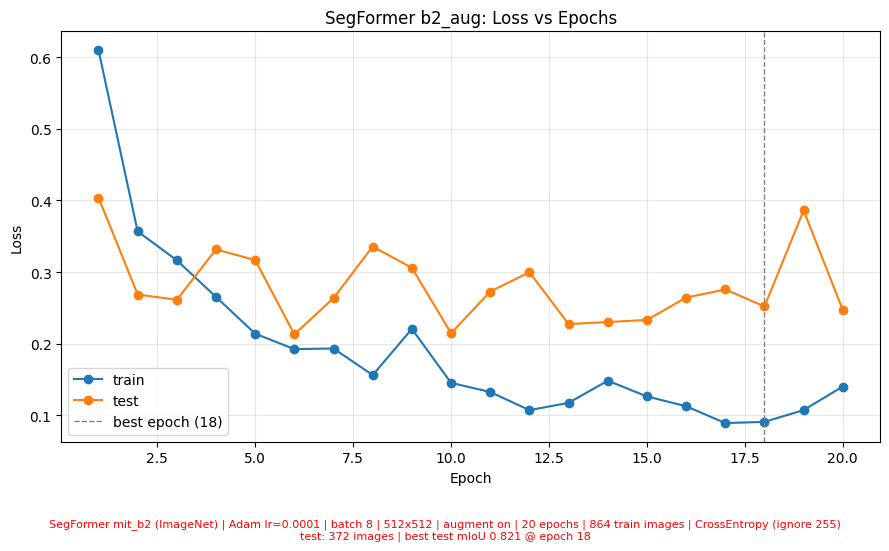

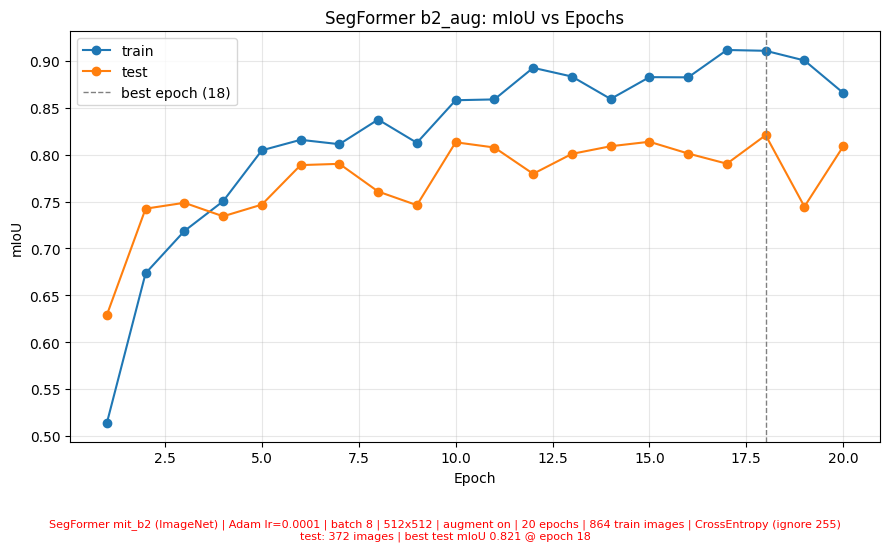

In [9]:
# Train every version with "run": True, then draw its graphs.
# A version with "run": False is still included in the comparison if it finished earlier.

histories = {}
for exp in EXPERIMENTS:
    if exp["run"]:
        histories[exp["name"]] = train_experiment(exp)
    elif is_finished(exp):
        print(f"{exp['name']}: not training, using the finished run saved in Drive")
        with open(f"{run_dir(exp)}/history.json") as f:
            histories[exp["name"]] = json.load(f)
    else:
        continue
    output_files += plot_history(exp, histories[exp["name"]])

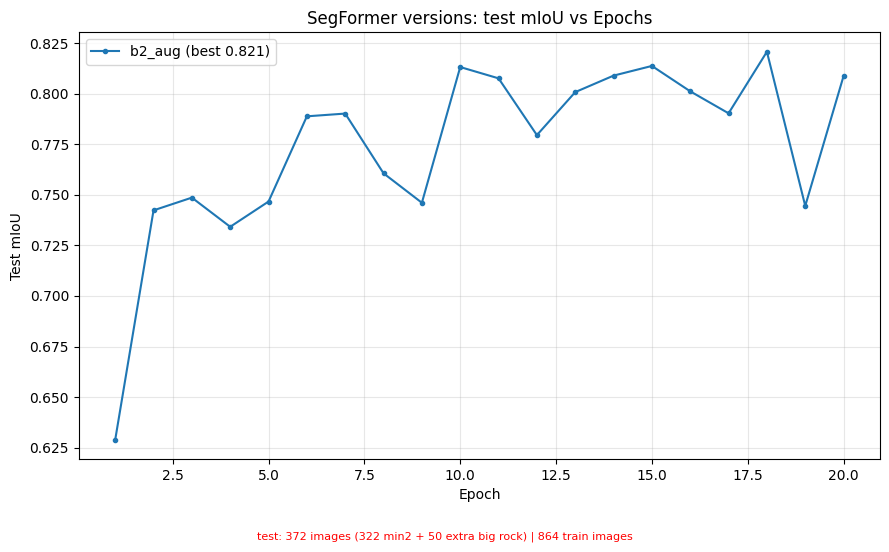

In [10]:
# All versions on one graph: test mIoU vs epochs

done = [exp for exp in EXPERIMENTS if exp["name"] in histories]
plt.figure(figsize=(9, 5.5))
for exp in done:
    h = histories[exp["name"]]
    plt.plot(range(1, len(h["test_miou"]) + 1), h["test_miou"], marker="o", markersize=3,
             label=f"{exp['name']} (best {max(h['test_miou']):.3f})")
plt.xlabel("Epoch")
plt.ylabel("Test mIoU")
plt.title("SegFormer versions: test mIoU vs Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.figtext(0.5, 0.01, f"test: {len(test_pairs)} images ({test_is_gold.sum()} min2 + {(~test_is_gold).sum()} extra big rock) | "
            f"{len(train_pairs)} train images", ha="center", color="red", fontsize=8)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("segformer_all_versions_miou.png", dpi=150)
plt.savefig(f"{RUNS_ROOT}/segformer_all_versions_miou.png", dpi=150)
plt.show()
output_files.append("segformer_all_versions_miou.png")

# Evaluation
Each version is loaded from its best epoch and scored on the test set. Big rock is also scored separately on the 50 extra big-rock images, since the min2 test images have very little big rock.

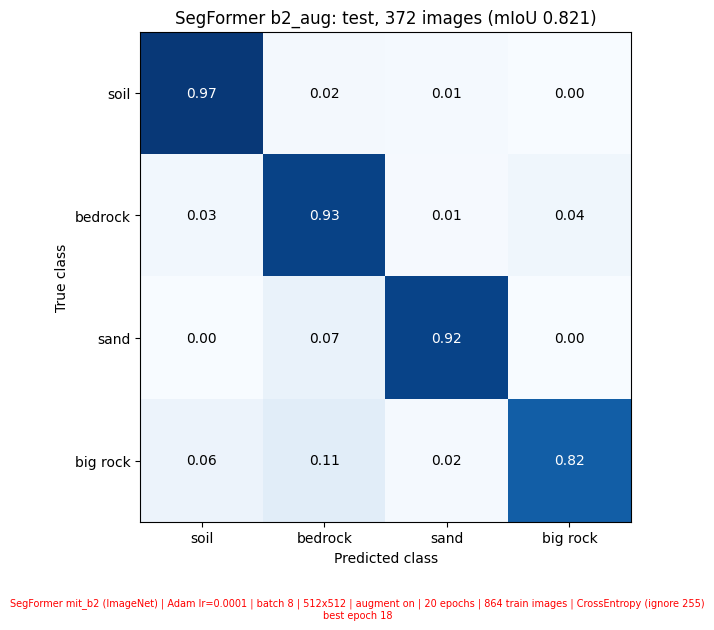

         test mIoU  soil IoU  bedrock IoU  sand IoU  big rock IoU  min2 mIoU  big rock IoU (extra 50)  big rock recall  best epoch  sec per epoch
version                                                                                                                                          
b2_aug       0.821     0.946        0.845     0.893           0.6      0.687                    0.755            0.823          18         58.091


In [11]:
# Per-class IoU and a confusion matrix for each version

def predict_loader(model, loader):
    """Confusion matrix for every image in loader, one per image (so subsets can be added up later)."""
    model.eval()
    per_image = []
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on):
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            preds = model(imgs).argmax(dim=1)
            for p, m in zip(preds, masks):
                per_image.append(count_pixels(p, m).cpu().numpy())
    return np.stack(per_image)

def load_trained(exp):
    model = build_model(exp, pretrained=False)
    model.load_state_dict(torch.load(f"{run_dir(exp)}/best_model.pt", map_location=device))
    model.eval()
    return model

rows = []
for exp in done:
    model = load_trained(exp)
    loader = make_loader(test_pairs, exp["size"], exp["batch_size"], shuffle=False)
    per_image = predict_loader(model, loader)
    cm_all, cm_gold, cm_extra = per_image.sum(0), per_image[test_is_gold].sum(0), per_image[~test_is_gold].sum(0)
    iou = iou_per_class(cm_all)
    h = histories[exp["name"]]
    rows.append({"version": exp["name"], "test mIoU": mean_iou(cm_all),
                 **{f"{c} IoU": v for c, v in zip(CLASS_NAMES, iou)},
                 "min2 mIoU": mean_iou(cm_gold),
                 "big rock IoU (extra 50)": iou_per_class(cm_extra)[3],
                 "big rock recall": cm_all[3, 3] / max(cm_all[3].sum(), 1),
                 "best epoch": int(np.argmax(h["test_miou"])) + 1,
                 "sec per epoch": float(np.mean(h["seconds"])) if h.get("seconds") else np.nan})

    # Confusion matrix as row percentages (each row sums to 1): what each true class gets predicted as
    pct = cm_all / np.maximum(cm_all.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7, 6.3))
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(f"SegFormer {exp['name']}: test, {len(test_pairs)} images (mIoU {mean_iou(cm_all):.3f})")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{pct[i, j]:.2f}", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black")
    fig.text(0.5, 0.01, settings_text(exp) + f"\nbest epoch {rows[-1]['best epoch']}",
             ha="center", color="red", fontsize=7)
    plt.tight_layout(rect=[0, 0.07, 1, 1])
    filename = f"segformer_{exp['name']}_confusion.png"
    plt.savefig(filename, dpi=150)
    plt.savefig(f"{run_dir(exp)}/{filename}", dpi=150)
    plt.show()
    output_files.append(filename)
    del model
    torch.cuda.empty_cache()

results = pd.DataFrame(rows).set_index("version")
print(results.round(3).to_string())
results.round(4).to_csv("segformer_results.csv")
results.round(4).to_csv(f"{RUNS_ROOT}/segformer_results.csv")
output_files.append("segformer_results.csv")

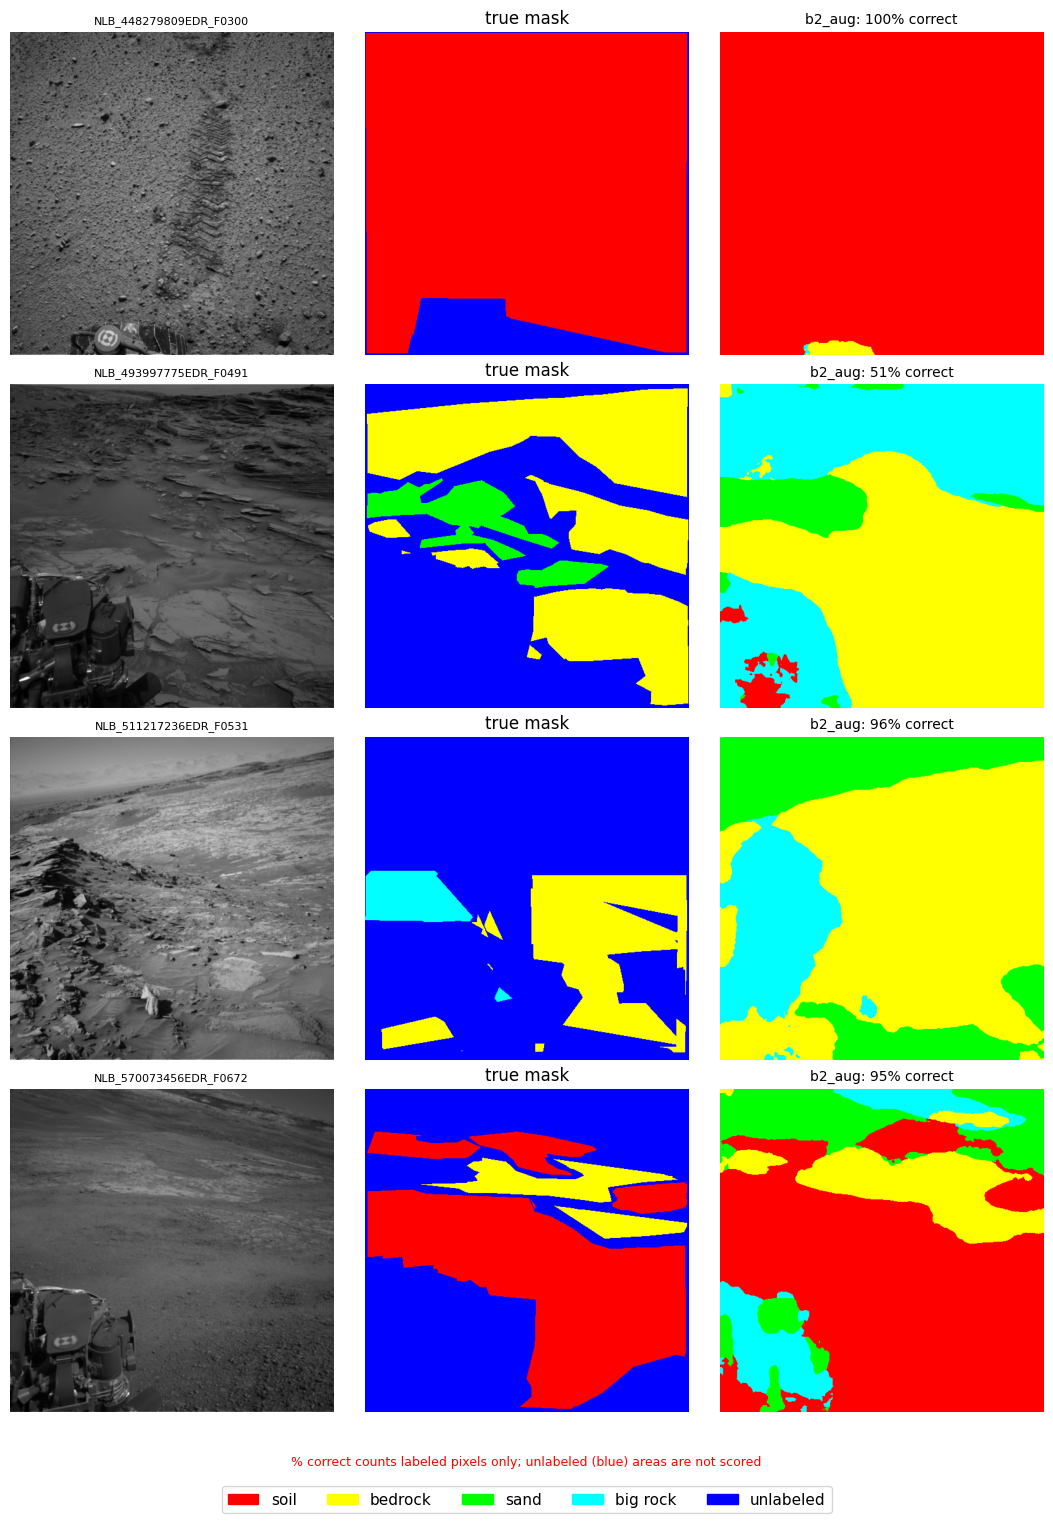

In [12]:
# Random test images: photo, true mask, and each version's prediction

def colorize(mask):
    out = np.zeros(mask.shape + (3,), dtype=np.uint8)
    for value, color in COLORS.items():
        out[mask == value] = color
    return out

picks = sorted(random.Random(EXAMPLE_SEED).sample(range(len(test_pairs)), N_EXAMPLES))
models = {exp["name"]: load_trained(exp) for exp in done}
show = 512   # display size

n_cols = 2 + len(done)
fig, axes = plt.subplots(N_EXAMPLES, n_cols, figsize=(3.6 * n_cols, 3.8 * N_EXAMPLES), squeeze=False)
with torch.no_grad():
    for row, idx in zip(axes, picks):
        img_path, mask_path = test_pairs[idx]
        true = load_mask(mask_path, show).numpy()
        labeled = true != IGNORE
        row[0].imshow(np.array(Image.open(img_path).convert("L").resize((show, show), Image.BILINEAR)), cmap="gray")
        row[0].set_title(os.path.basename(img_path)[:22], fontsize=8)
        row[1].imshow(colorize(true))
        row[1].set_title("true mask")
        for ax, exp in zip(row[2:], done):
            logits = models[exp["name"]](load_image(img_path, exp["size"]).unsqueeze(0).to(device))
            pred = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
            pred = np.array(Image.fromarray(pred).resize((show, show), Image.NEAREST))
            correct = (pred[labeled] == true[labeled]).mean() if labeled.any() else float("nan")
            ax.imshow(colorize(pred))
            ax.set_title(f"{exp['name']}: {correct:.0%} correct", fontsize=10)
        for ax in row:
            ax.axis("off")

legend = [Patch(color=np.array(COLORS[k]) / 255, label=n)
          for k, n in [(0, "soil"), (1, "bedrock"), (2, "sand"), (3, "big rock"), (255, "unlabeled")]]
fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=11)
fig.text(0.5, 0.035, "% correct counts labeled pixels only; unlabeled (blue) areas are not scored",
         ha="center", color="red", fontsize=9)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("segformer_random_test_examples.png", dpi=120)
plt.savefig(f"{RUNS_ROOT}/segformer_random_test_examples.png", dpi=120)
plt.show()
output_files.append("segformer_random_test_examples.png")
del models
torch.cuda.empty_cache()

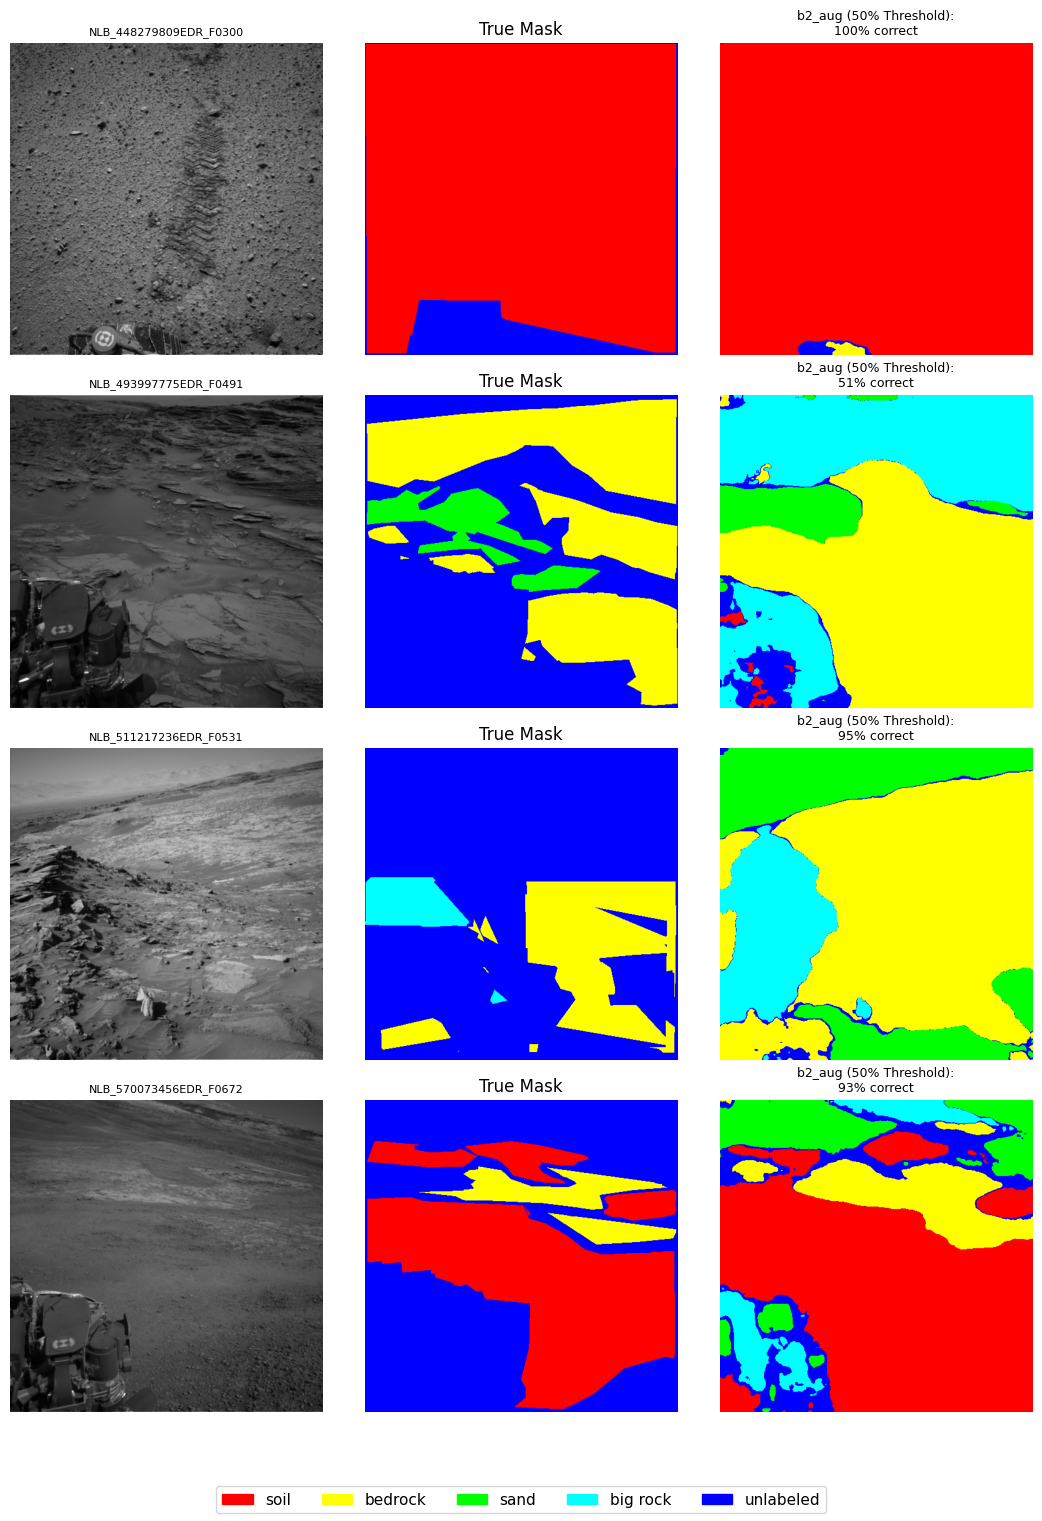

In [18]:
CONF_THRESHOLD = 0.5 # Filter out predictions with less than 85% confidence

models = {exp["name"]: load_trained(exp) for exp in done}
show = 512

fig, axes = plt.subplots(N_EXAMPLES, n_cols, figsize=(3.6 * n_cols, 3.8 * N_EXAMPLES), squeeze=False)
with torch.no_grad():
    for row, idx in zip(axes, picks):
        img_path, mask_path = test_pairs[idx]
        true = load_mask(mask_path, show).numpy()
        labeled = true != IGNORE

        # Original Input Image
        row[0].imshow(np.array(Image.open(img_path).convert("L").resize((show, show), Image.BILINEAR)), cmap="gray")
        row[0].set_title(os.path.basename(img_path)[:22], fontsize=8)

        # True Mask
        row[1].imshow(colorize(true))
        row[1].set_title("True Mask")

        # Model Predictions with Confidence Thresholding
        for ax, exp in zip(row[2:], done):
            logits = models[exp["name"]](load_image(img_path, exp["size"]).unsqueeze(0).to(device))

            # Apply Softmax to get probabilities
            probs = torch.softmax(logits, dim=1)
            max_probs, preds = torch.max(probs, dim=1)

            pred = preds[0].cpu().numpy().astype(np.uint8)
            conf = max_probs[0].cpu().numpy()

            # Resize prediction and confidence to display resolution
            pred_resized = np.array(Image.fromarray(pred).resize((show, show), Image.NEAREST))
            conf_resized = np.array(Image.fromarray(conf).resize((show, show), Image.BILINEAR))

            # Set low-confidence pixels to IGNORE (255)
            pred_resized[conf_resized < CONF_THRESHOLD] = IGNORE

            # Visual score (only counting actual labeled pixels)
            correct = (pred_resized[labeled] == true[labeled]).mean() if labeled.any() else float("nan")

            ax.imshow(colorize(pred_resized))
            ax.set_title(f"{exp['name']} ({CONF_THRESHOLD*100:.0f}% Threshold):\n{correct:.0%} correct", fontsize=9)

        for ax in row:
            ax.axis("off")

legend = [Patch(color=np.array(COLORS[k]) / 255, label=n)
          for k, n in [(0, "soil"), (1, "bedrock"), (2, "sand"), (3, "big rock"), (255, "unlabeled")]]
fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=11)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

del models
torch.cuda.empty_cache()

In [15]:
# Export the best version (highest test mIoU) for the Streamlit demo.
# Weights are saved in half precision to keep the file small enough for GitHub (under 100 MB).

best_name = results["test mIoU"].idxmax()
best_exp = next(exp for exp in done if exp["name"] == best_name)
print("best version:", best_name)
print(results.loc[best_name].round(3).to_string())

state = torch.load(f"{run_dir(best_exp)}/best_model.pt", map_location="cpu")
torch.save({k: v.half() if v.is_floating_point() else v for k, v in state.items()}, "segformer_best.pt")
config = {
    "version": best_name,
    "encoder": best_exp["encoder"],
    "size": best_exp["size"],
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "colors": {str(k): v for k, v in COLORS.items()},
    "mean": [round(float(x), 3) for x in MEAN],
    "std": [round(float(x), 3) for x in STD],
    "test_miou": round(float(results.loc[best_name, "test mIoU"]), 4),
    "test_iou": {c: round(float(results.loc[best_name, f"{c} IoU"]), 4) for c in CLASS_NAMES},
    "n_test_images": len(test_pairs),
}
with open("segformer_best.json", "w") as f:
    json.dump(config, f, indent=2)
for f in ["segformer_best.pt", "segformer_best.json"]:
    shutil.copy(f, EXPORT_DIR)
print("weights size:", round(os.path.getsize("segformer_best.pt") / 1e6, 1), "MB")
print("also saved in", EXPORT_DIR)
output_files += ["segformer_best.pt", "segformer_best.json"]

best version: b2_aug
test mIoU                   0.821
soil IoU                    0.946
bedrock IoU                 0.845
sand IoU                    0.893
big rock IoU                0.600
min2 mIoU                   0.687
big rock IoU (extra 50)     0.755
big rock recall             0.823
best epoch                 18.000
sec per epoch              58.091
weights size: 49.6 MB
also saved in /content/drive/MyDrive/segformer_runs_v2/streamlit


In [16]:
# Download everything (the browser may ask to allow multiple downloads)

from google.colab import files

for f in output_files:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>